# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Sidqi Raafi Al Fauzan
- **Email:** sidqiraf123@gmail.com
- **ID Dicoding:** ds764b6y1663

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Apa saja 5 kategori produk yang menghasilkan total pendapatan (revenue) tertinggi dan terendah sepanjang tahun 2017?

- **Pertanyaan 2:** Bagaimana dampak keterlambatan pengiriman pesanan (terlambat dibandingkan dengan tepat waktu) terhadap rata-rata skor ulasan (review score) pelanggan pada seluruh periode data (2016-2018)?

## Import Semua Packages/Library yang Digunakan

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df E-Commerce Public Dataset

In [46]:
# memuat seluruh tabel E-Commerce public dataset
customers_df = pd.read_csv('data/customers_dataset.csv')
orders_df = pd.read_csv('data/orders_dataset.csv')
order_items_df = pd.read_csv('data/order_items_dataset.csv')
order_payments_df = pd.read_csv('data/order_payments_dataset.csv')
order_reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
products_df = pd.read_csv('data/products_dataset.csv')
category_trans_df = pd.read_csv('data/product_category_name_translation.csv')
sellers_df = pd.read_csv('data/sellers_dataset.csv')
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')

# Menampilkan informasi dimensi data
print(f"Total baris geolocation mentah: {len(geolocation_df)}")

Total baris geolocation mentah: 1000163


**Insight:** (Opsional)
- seluruh tabel data relasional seperti `customers_df`, `geolocation_df`, `order_items_df`, `order_payments_df`, `orders_df`, `category_trans_df`, `products_df`, dan `sellers_df` sudah berhasil dimuat ke dalam DataFrame Pandas.

- tabel `geolocation_df` yang berukuran paling besar memiliki volume data paling signifikan di angka 1.000.163 baris, dataset ini akan dipersiapkan untuk proses agregasi serta pemetaan geospasial pada tahap selanjutnya.

### Assessing Data

#### Identifying E-Commerce Public Dataset problem

In [47]:
# Membuat dictionary
datasets = {
    "Customers": customers_df,
    "Orders": orders_df,
    "Order Items": order_items_df,
    "Payments": order_payments_df,
    "Reviews": order_reviews_df,
    "Products": products_df,
    "Translations": category_trans_df,
    "Sellers": sellers_df,
    "Geolocation": geolocation_df
}

# Loop untuk mencetak ringkasan masalah (Tipe Data, Missing Value, Duplikasi)
for name, df in datasets.items():
    print(f"=== {name} ===")
    print(f"Bentuk (Shape): {df.shape}")
    print(f"Duplikasi: {df.duplicated().sum()}")

    # Menampilkan kolom yang memiliki missing value saja
    missing_cols = df.isna().sum()[df.isna().sum() > 0]
    if not missing_cols.empty:
        print("Missing Values:")
        print(missing_cols)
    else:
        print("Missing Values: 0")

    print("-" * 40)

# Cek spesifik tipe data pada tabel Orders (karena sering ada masalah tanggal)
print("\nTipe Data Tabel Orders:")
print(orders_df.dtypes)

# Cek parameter statistik numerik untuk mendeteksi outlier
print("\n=== Ringkasan Statistik Order Items (Cek Outlier Harga & Ongkir) ===")
print(order_items_df[['price', 'freight_value']].describe())

print("\n=== Ringkasan Statistik Payments (Cek Outlier Pembayaran) ===")
print(order_payments_df[['payment_installments', 'payment_value']].describe())

# Cek konsistensi nilai kategori
print("\n=== Status Pesanan Unik pada Orders ===")
print(orders_df['order_status'].value_counts())

# Menghitung batas outlier kolom price dengan metode IQR
q25 = order_items_df['price'].quantile(0.25)
q75 = order_items_df['price'].quantile(0.75)
iqr = q75 - q25

lower_bound = q25 - (1.5 * iqr)
upper_bound = q75 + (1.5 * iqr)

outliers_price = order_items_df[(order_items_df['price'] < lower_bound) | (order_items_df['price'] > upper_bound)]

print("\n=== Menghitung batas outlier menggunakan metode IQR ===")
print(f"Batas bawah IQR : {lower_bound:.2f}")
print(f"Batas atas IQR  : {upper_bound:.2f}")
print(f"Jumlah outlier harga: {len(outliers_price)} ({(len(outliers_price) / len(order_items_df)) * 100:.2f}%)")

=== Customers ===
Bentuk (Shape): (99441, 5)
Duplikasi: 0
Missing Values: 0
----------------------------------------
=== Orders ===
Bentuk (Shape): (99441, 8)
Duplikasi: 0
Missing Values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
----------------------------------------
=== Order Items ===
Bentuk (Shape): (112650, 7)
Duplikasi: 0
Missing Values: 0
----------------------------------------
=== Payments ===
Bentuk (Shape): (103886, 5)
Duplikasi: 0
Missing Values: 0
----------------------------------------
=== Reviews ===
Bentuk (Shape): (99224, 7)
Duplikasi: 0
Missing Values:
review_comment_title      87656
review_comment_message    58247
dtype: int64
----------------------------------------
=== Products ===
Bentuk (Shape): (32951, 9)
Duplikasi: 0
Missing Values:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_

**Steps to Take:**
- **memperbaiki tipe data:** mengonversi seluruh kolom yang merepresentasikan waktu pada tabel `orders_df` dari tipe data object menjadi tipe data datetime.

- **menangani duplicate data:** menghapus 261.831 baris data duplikat yang ada pada tabel `geolocation_df` agar tidak membebani memori dan proses komputasi.

- **menangani missing values:**
  - pada tabel `orders_df`, nilai kosong pada tanggal pengiriman menjadi hal yang wajar untuk berstatus cancelled atau unavailable, disini saya hanya akan memfilter pesanan dengan status delivered untuk analisis utama.
  - pada tabel `products_df`, mengisi 610 nilai kosong di kolom `product_category_name` dengan label "unknown" atau "other", mengisi 610 nilai kosong pada metadata produk dan menghapus / mengisi nilai kosong pada dimensi produk.
  - pada tabel `order_reviews_df`, membiarkan nilai kosong pada judul dan pesan ulasan karena analisis kepuasan pelanggan hanya akan berfokus pada kolom review_score.

- **menangani outlier:** mempertahankan angka outlier sebanyak 8.427 baris (7.48%) di kolom price. angka ini merupakan outlier natural yang menunjukan transaksi bernilai tinggi yang bukan merupakan kesalahan input sistem contohnya seperti transaksi produk elektronik atau furnitur.

**Insight:** (Opsional)
- ada beberapa anomali data, seperti kesalahan tipe data pada kolom tanggal, banyaknya duplikasi di pada tabel `geolocation_df`, serta nilai kosong (missing values) pada tabel `orders_df`, `order_reviews_df`, dan `products_df`.

- mayoritas pesanan (96.478) telah berstatus delivered, sehingga data ini bisa digunakan untuk menjawab pertanyaan analisis terkait durasi pengiriman.

- terdapat outlier pada harga barang dengan batas atas di angka 277.40, tapi data tersebut tetap dipertahankan untuk menjaga keakuratan total pendapatan.

### Cleaning Data

#### Fixing E-Commerce Public Dataset problem

In [48]:
# 1. Memperbaiki Tipe Data pada tabel orders_df
datetime_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Menangani Duplicate Data pada tabel geolocation_df
geolocation_df.drop_duplicates(inplace=True)

# 3. Menangani Missing Values
# 3a. Memfilter orders_df hanya pesanan dengan status 'delivered'
orders_df = orders_df[orders_df['order_status'] == 'delivered'].copy()

# 3b. Mengisi missing value kategori produk dengan label "Unknown"
products_df['product_category_name'] = products_df['product_category_name'].fillna('Unknown')

# 3c. Mengisi missing value metadata produk dengan 0
products_df['product_name_lenght'] = products_df['product_name_lenght'].fillna(0)
products_df['product_description_lenght'] = products_df['product_description_lenght'].fillna(0)
products_df['product_photos_qty'] = products_df['product_photos_qty'].fillna(0)

# 3d. Menghapus 2 baris yang tidak memiliki informasi dimensi fisik
products_df.dropna(subset=[
    'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm'
], inplace=True)

# 4. Verifikasi hasil pembersihan
print("=== HASIL PEMBERSIHAN DATA ===")
print("Sisa missing values pada products_df:")
print(products_df.isna().sum())
print("-" * 30)
print(f"Total baris orders_df (status delivered): {len(orders_df):,}")

=== HASIL PEMBERSIHAN DATA ===
Sisa missing values pada products_df:
product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64
------------------------------
Total baris orders_df (status delivered): 96,478


**Insight: (Opsional)**
* Seluruh kolom waktu pada tabel `orders_df` telah berhasil dikonversi menjadi tipe data `datetime` sehingga siap digunakan untuk operasi perhitungan selisih waktu (durasi pengiriman).

* Tabel `products_df` sudah bersih sepenuhnya (0 *missing values*) setelah dilakukan imputasi nilai "Unknown" pada kategori, pengisian angka 0 pada metadata, dan penghapusan 2 baris anomali.

* Tabel `orders_df` telah disaring dan kini menyisakan 96.478 baris pesanan dengan status *delivered*, yang merupakan data digunakan untuk menganalisis performa pengiriman dan kepuasan pelanggan.

* Ratusan ribu duplikasi pada tabel `geolocation_df` telah dihapus sehingga kini jauh lebih ringan dan efisien untuk diproses pada tahap pemetaan.

## Exploratory Data Analysis (EDA)

### Explore E-Commerce Public Dataset

In [49]:
# EDA PERTANYAAN 1: Pendapatan (Revenue) Kategori Produk Tertinggi & Terendah 2017

# 1. Filter pesanan yang terjadi hanya pada tahun 2017
orders_2017 = orders_df[orders_df['order_purchase_timestamp'].dt.year == 2017]

# 2. Gabungkan tabel item pesanan dengan produk, lalu dengan translasi bahasa Inggris
item_prod_df = pd.merge(order_items_df, products_df, on='product_id', how='left')
item_prod_trans_df = pd.merge(item_prod_df, category_trans_df, on='product_category_name', how='left')

# 2a. Jika translasi bahasa Inggris kosong, gunakan nama aslinya
item_prod_trans_df['product_category_name_english'] = item_prod_trans_df['product_category_name_english'].fillna(item_prod_trans_df['product_category_name'])

# 3. Gabungkan pesanan 2017 dengan detail item-produknya
sales_2017 = pd.merge(orders_2017, item_prod_trans_df, on='order_id', how='inner')

# 4. Agregasi total pendapatan berdasarkan kategori produk
revenue_category = sales_2017.groupby('product_category_name_english')['price'].sum().reset_index()
revenue_category.rename(columns={'price': 'total_revenue'}, inplace=True)
revenue_category = revenue_category.sort_values(by='total_revenue', ascending=False)

print("=== Top 5 Kategori dengan Pendapatan Tertinggi (2017) ===")
print(revenue_category.head())
print("\n=== Top 5 Kategori dengan Pendapatan Terendah (2017) ===")
print(revenue_category.tail())

# EDA PERTANYAAN 2: Dampak Keterlambatan Pengiriman terhadap Skor Ulasan

# 1. Menentukan apakah sebuah pesanan datang terlambat
orders_df['is_late'] = orders_df['order_delivered_customer_date'] > orders_df['order_estimated_delivery_date']
orders_df['delivery_status'] = orders_df['is_late'].map({True: 'Terlambat', False: 'Tepat Waktu'})

# 2. Gabungkan data pesanan dengan tabel ulasan pelanggan
order_reviews_merged = pd.merge(orders_df, order_reviews_df, on='order_id', how='inner')

# 3. Agregasi rata-rata skor ulasan berdasarkan status keterlambatan
review_by_delivery = order_reviews_merged.groupby('delivery_status')['review_score'].agg(['mean', 'count']).reset_index()
review_by_delivery.rename(columns={'mean': 'average_review_score', 'count': 'total_orders'}, inplace=True)
review_by_delivery['average_review_score'] = review_by_delivery['average_review_score'].round(2)

print("\n=== Rata-rata Skor Ulasan berdasarkan Status Pengiriman ===")
print(review_by_delivery)

=== Top 5 Kategori dengan Pendapatan Tertinggi (2017) ===
   product_category_name_english  total_revenue
8                 bed_bath_table      490596.92
72                 watches_gifts      475610.71
44                 health_beauty      473833.00
67                sports_leisure      435674.14
16         computers_accessories      391786.29

=== Top 5 Kategori dengan Pendapatan Terendah (2017) ===
   product_category_name_english  total_revenue
30     fashion_childrens_clothes         349.98
63         security_and_services         283.29
36                       flowers         270.50
4          arts_and_craftmanship         151.89
24           diapers_and_hygiene          76.00

=== Rata-rata Skor Ulasan berdasarkan Status Pengiriman ===
  delivery_status  average_review_score  total_orders
0     Tepat Waktu                  4.29         88661
1       Terlambat                  2.57          7700


**Insight: (Opsional)**
* **Kinerja Kategori (2017):** Pendapatan didominasi oleh kategori perlengkapan rumah tangga dan gaya hidup, yaitu `bed_bath_table`, `watches_gifts`, `health_beauty`, `sports_leisure`, dan `computers_accessories`, dengan total pendapatan tertinggi 490596.92 BRL hingga 391786.29 BRL. Sebaliknya, kategori seperti `fashion_childrens_clothes` dan `diapers_and_hygiene` mencatat pendapatan tahunan terendah, di kisaran 349.98 BRL hingga 76 BRL.

* **Dampak Keterlambatan Pengiriman (2016-2018):** Sebanyak 92% pesanan tiba tepat waktu, sedangkan 8% sisanya terlambat. Rata-rata skor ulasan turun dari 4.29 pada pesanan tepat waktu menjadi 2.57 pada pesanan terlambat. Pola ini menunjukkan hubungan yang kuat antara keterlambatan pengiriman dan ulasan yang buruk, meskipun faktor lain (misalnya kualitas produk) belum dianalisis.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

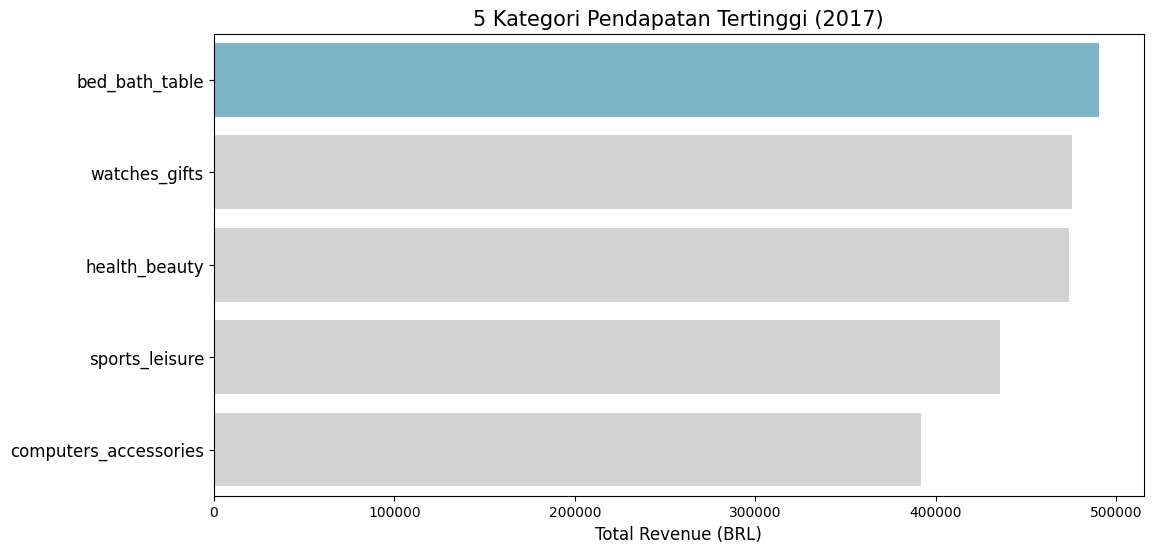

In [50]:
# Mengatur palet warna
colors = ["#72BCD4", "#D3D3D3", "#D3D3D3", "#D3D3D3", "#D3D3D3"]

plt.figure(figsize=(12, 6))

# Plot Top 5 Kategori
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    hue="product_category_name_english",
    data=revenue_category.head(5),
    palette=colors,
    legend=False
)

plt.ylabel(None)
plt.xlabel("Total Revenue (BRL)", fontsize=12)
plt.title("5 Kategori Pendapatan Tertinggi (2017)", loc="center", fontsize=15)
plt.tick_params(axis='y', labelsize=12)
plt.show()

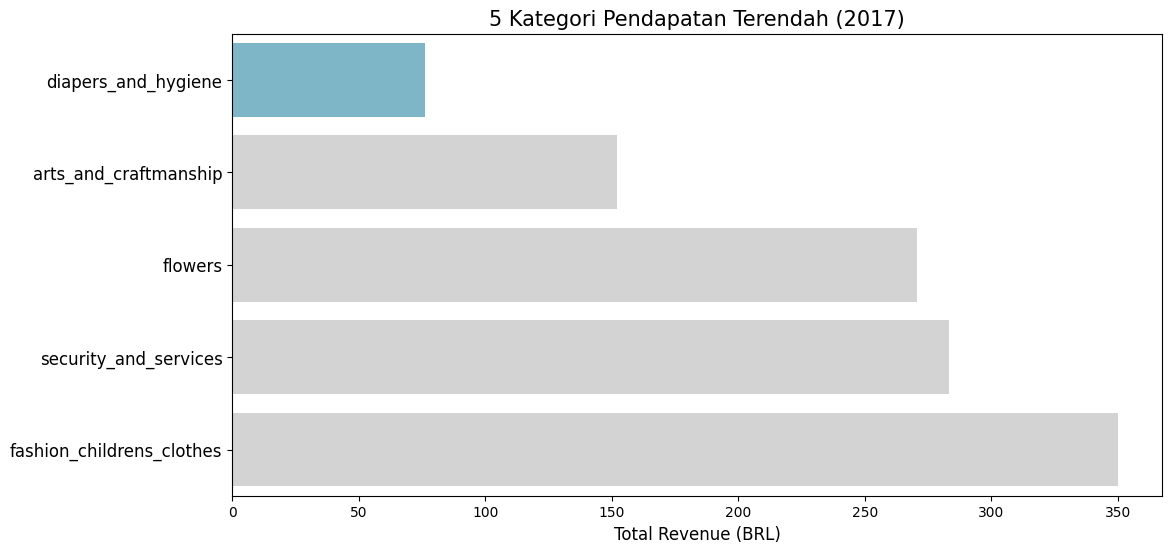

In [51]:
plt.figure(figsize=(12, 6))

# Plot Bottom 5 Kategori
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    hue="product_category_name_english",
    data=revenue_category.tail(5).sort_values(by='total_revenue', ascending=True),
    palette=colors,
    legend=False
)

plt.ylabel(None)
plt.xlabel("Total Revenue (BRL)", fontsize=12)
plt.title("5 Kategori Pendapatan Terendah (2017)", loc="center", fontsize=15)
plt.tick_params(axis='y', labelsize=12)
plt.show()

### Pertanyaan 2:

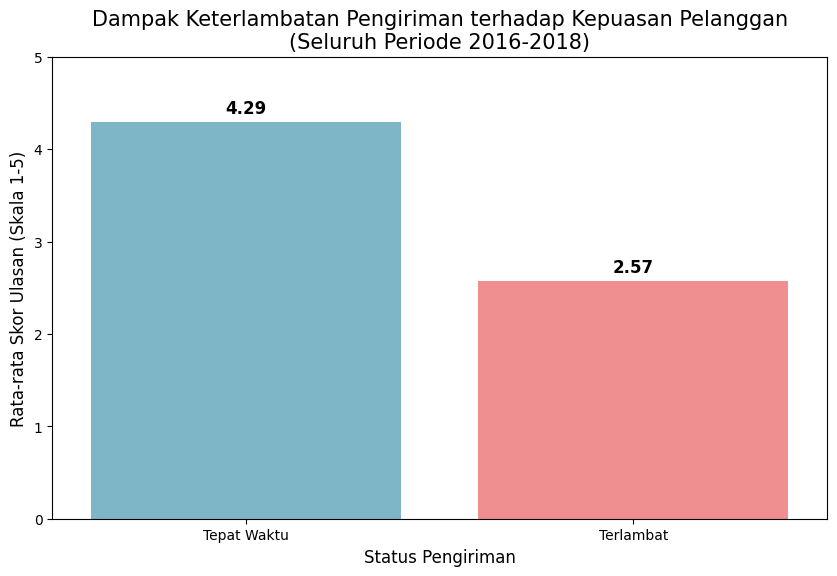

In [52]:
plt.figure(figsize=(10, 6))

# palet warna
colors_delivery = ["#72BCD4", "#FF7F7F"]

# Membuat Barplot
barplot = sns.barplot(
    x="delivery_status",
    y="average_review_score",
    hue="delivery_status",
    data=review_by_delivery,
    palette=colors_delivery,
    legend=False
)

plt.title("Dampak Keterlambatan Pengiriman terhadap Kepuasan Pelanggan\n(Seluruh Periode 2016-2018)", fontsize=15)
plt.xlabel("Status Pengiriman", fontsize=12)
plt.ylabel("Rata-rata Skor Ulasan (Skala 1-5)", fontsize=12)
plt.ylim(0, 5) # Skala ulasan maksimal 5

# Menambahkan label angka di atas setiap bar
for index, row in review_by_delivery.iterrows():
    plt.text(index, row.average_review_score + 0.1, f"{row.average_review_score}", color='black', ha="center", fontsize=12, fontweight='bold')

plt.show()

**Insight:**
* **Pertanyaan 1:** Berdasarkan visualisasi grafik pendapatan, kategori `bed_bath_table` memimpin sebagai penyumbang omzet tertinggi pada tahun 2017 dengan perolehan 490596.92 BRL. Sebaliknya, kategori `diapers_and_hygiene` mencatatkan performa penjualan yang paling rendah di angka 76 BRL. Perbedaan yang signifikan ini mengindikasikan bahwa pendapatan platform didominasi oleh perlengkapan rumah tangga dan gaya hidup.

* **Pertanyaan 2:** Visualisasi rata-rata skor ulasan pada seluruh periode data (2016-2018) menunjukkan bahwa pesanan yang tiba "Tepat Waktu" mendapatkan skor ulasan yang tinggi, yaitu 4.29 dari skala 5. Pesanan berstatus "Terlambat" memiliki skor yang jauh lebih rendah, yaitu 2.57. Selisih sekitar 1.7 poin ini menunjukkan bahwa keterlambatan pengiriman berkaitan erat dengan turunnya kepuasan pelanggan. Analisis ini membandingkan rata-rata dua kelompok, sehingga menunjukkan hubungan dan bukan bukti sebab-akibat.

## Analisis Lanjutan (Opsional)

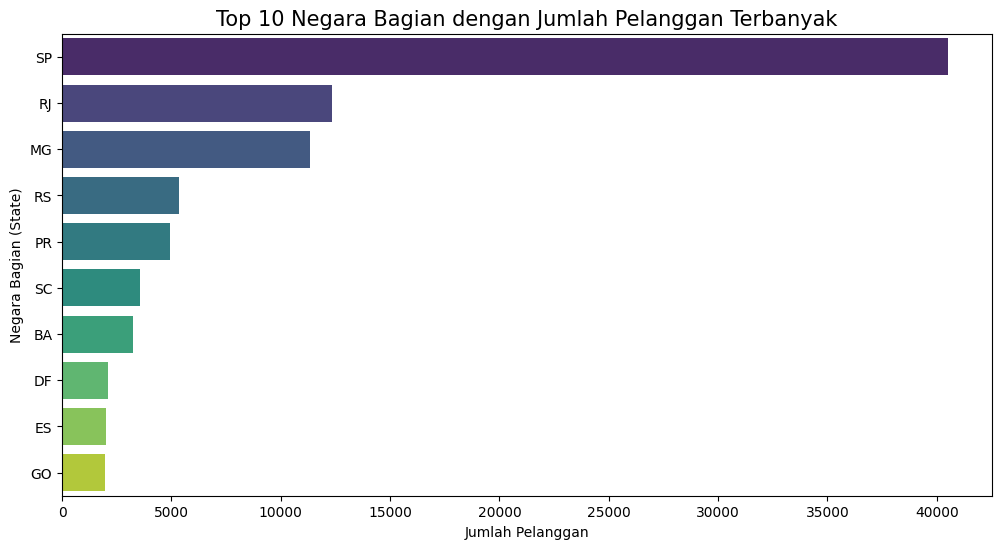

In [53]:
# Analisis Geospasial: Distribusi Pelanggan per Negara Bagian (Top 10)
# Hanya pelanggan yang memiliki pesanan berstatus delivered (konsisten dengan dashboard)
cust_delivered = customers_df[customers_df['customer_id'].isin(orders_df['customer_id'])]

bystate_df = cust_delivered.groupby(by="customer_state").customer_id.nunique().reset_index()
bystate_df.rename(columns={"customer_id": "customer_count"}, inplace=True)
bystate_df = bystate_df.sort_values(by="customer_count", ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    x="customer_count",
    y="customer_state",
    data=bystate_df.head(10),
    palette="viridis",
    hue="customer_state",
    legend=False
)
plt.title("Top 10 Negara Bagian dengan Jumlah Pelanggan Terbanyak", fontsize=15)
plt.xlabel("Jumlah Pelanggan")
plt.ylabel("Negara Bagian (State)")
plt.show()

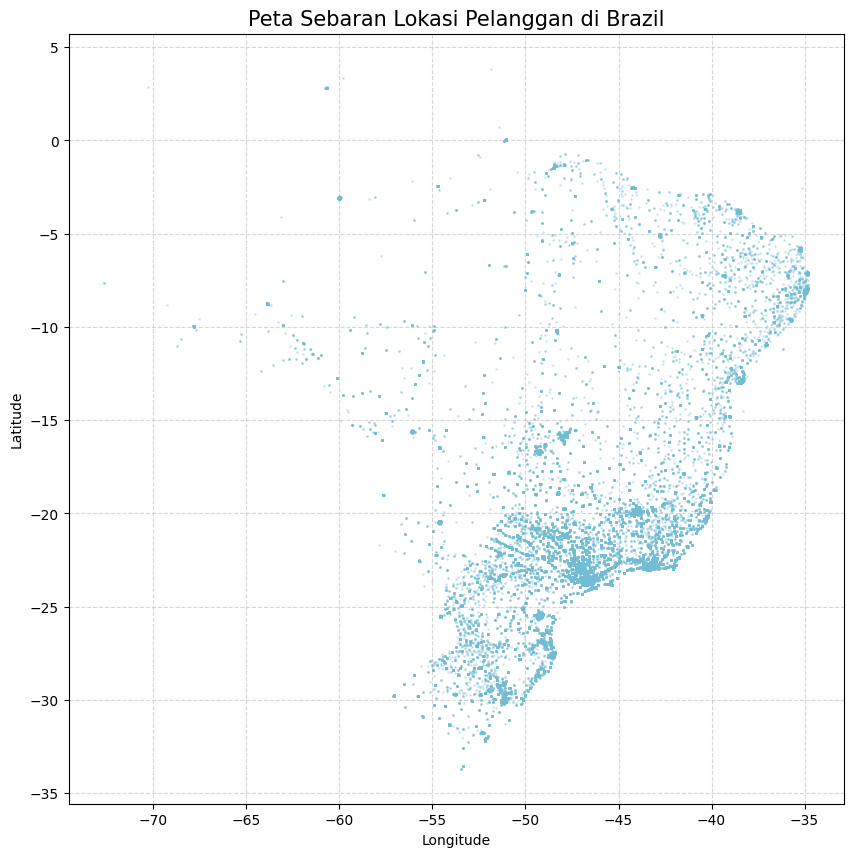

In [54]:
# Rata-rata koordinat per kode pos, lalu petakan pelanggan yang memiliki pesanan delivered
geo_zip = geolocation_df.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean().reset_index()

cust_geo = customers_df[customers_df['customer_id'].isin(orders_df['customer_id'])].merge(
    geo_zip, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left'
).dropna(subset=['geolocation_lat'])

cust_geo = cust_geo[
    cust_geo['geolocation_lat'].between(-33.751169, 5.274388) &
    cust_geo['geolocation_lng'].between(-73.982830, -34.793147)
]

plt.figure(figsize=(10, 10))
plt.scatter(cust_geo['geolocation_lng'], cust_geo['geolocation_lat'], alpha=0.25, s=1, c='#72BCD4')
plt.title('Peta Sebaran Lokasi Pelanggan di Brazil', fontsize=15)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Insight:** (Opsional)
- Analisis geospasial digunakan untuk mengetahui pola sebaran wilayah pelanggan dan titik lokasi kode pos di Brazil, sehingga strategi logistik dan promosi dapat difokuskan pada wilayah dengan konsentrasi pasar tertinggi.

- Berdasarkan visualisasi barchart, basis pelanggan e-commerce sangat didominasi oleh negara bagian SP (São Paulo) dengan jumlah melampaui 40.000 pelanggan, diikuti oleh RJ (Rio de Janeiro) dan MG (Minas Gerais).

- Dominasi ini dikonfirmasi secara visual melalui peta distribusi titik (scatter plot), di mana konsentrasi titik koordinat terlihat sangat masif dan padat di area pesisir tenggara hingga selatan Brazil, yang merupakan pusat kepadatan penduduk dan pusat perekonomian negara tersebut. Wilayah utara dan barat terpantau memiliki sebaran pelanggan yang jauh lebih renggang.

## Conclusion & Recommendation

**Conclusion & Recommendation**

* **Conclusion Pertanyaan 1:** Performa pendapatan antar-kategori produk di tahun 2017 menunjukkan ketimpangan yang sangat signifikan. Kategori perlengkapan rumah (`bed_bath_table`) dan gaya hidup (`watches_gifts`, `health_beauty`) memimpin sebagai kontributor omzet tertinggi dengan perolehan masing-masing mendekati 500.000 BRL. Sebaliknya, kategori seperti `diapers_and_hygiene` dan `arts_and_craftmanship` berkontribusi sangat kecil dengan total omzet setahun penuh di bawah 200 BRL.

* **Conclusion Pertanyaan 2:** Pada seluruh periode data (2016-2018), ketepatan waktu pengiriman berkaitan erat dengan kepuasan pelanggan. Sebanyak 92% pesanan tiba tepat waktu dengan rata-rata skor ulasan 4.29, sedangkan 8% pesanan yang terlambat hanya memperoleh rata-rata skor 2.57. Selisih yang besar ini menunjukkan bahwa keterlambatan pengiriman adalah titik lemah layanan yang perlu diprioritaskan, meskipun faktor lain belum diuji dalam analisis ini.

* **Conclusion Analisis Lanjutan (Geospasial):** Basis pelanggan platform e-commerce ini sangat terpusat di wilayah pesisir tenggara hingga selatan Brazil. Negara bagian São Paulo (SP) menjadi penyumbang pelanggan terbesar secara mutlak (lebih dari 40.000 pelanggan), diikuti oleh Rio de Janeiro (RJ) dan Minas Gerais (MG).

**Rekomendasi Action Item:**
1. **Optimasi Inventaris dan Promosi Kategori:** Alokasikan porsi anggaran marketing yang lebih besar dan pastikan ketersediaan stok di gudang untuk top 3 kategori unggulan. Sebaliknya, lakukan audit profitabilitas pada 5 kategori terbawah; jika biaya operasionalnya melebihi pendapatan pertimbangkan untuk menghapus kategori tersebut dari katalog utama.

2. **Pengetatan SLA Kurir Logistik:** Segera lakukan evaluasi operasional terhadap mitra ekspedisi yang menangani pengiriman lambat. Platform perlu memberlakukan *Service Level Agreement* (SLA) yang lebih ketat atau memberikan kompensasi otomatis (seperti voucer diskon) kepada pelanggan yang terdampak keterlambatan untuk meredam potensi ulasan bintang 1 atau 2.

3. **Fokus Anggaran Kampanye Regional:** Hindari mendistribusikan anggaran iklan secara merata ke seluruh Brazil. Prioritaskan target iklan ke São Paulo (SP), Rio de Janeiro (RJ), dan Minas Gerais (MG) karena ketiga wilayah ini memiliki jumlah pelanggan terbanyak. Pertimbangkan juga analisis pendapatan per negara bagian untuk memastikan wilayah tersebut memang memberikan kontribusi omzet terbesar.

## Persiapan Data untuk Dashboard

Bagian ini menggabungkan tabel-tabel yang sudah dibersihkan menjadi satu berkas `main_data.csv` yang digunakan oleh dashboard Streamlit. Kolom `is_item_row` dan `is_review_row` menandai satu baris per item pesanan dan satu baris per ulasan, sehingga agregasi di dashboard menghasilkan angka yang sama dengan analisis di notebook ini.

In [56]:
## Persiapan Data untuk Dashboard
import os

# Rata-rata koordinat per kode pos
geo_zip = (geolocation_df
           .groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']]
           .mean()
           .rename(columns={'geolocation_lat': 'customer_geo_lat', 'geolocation_lng': 'customer_geo_lng'})
           .reset_index())

main_df = (orders_df
    .merge(order_items_df, on='order_id', how='left')
    .merge(products_df[['product_id', 'product_category_name']], on='product_id', how='left')
    .merge(category_trans_df, on='product_category_name', how='left')
    .merge(order_reviews_df[['order_id', 'review_id', 'review_score']], on='order_id', how='left')
    .merge(customers_df[['customer_id', 'customer_state', 'customer_zip_code_prefix']], on='customer_id', how='left')
    .merge(geo_zip, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left'))

main_df['product_category_name_english'] = main_df['product_category_name_english'].fillna(main_df['product_category_name'])

# Penanda baris agar agregasi di dashboard sama dengan notebook
main_df['is_item_row'] = ~main_df.duplicated(['order_id', 'order_item_id'])
main_df['is_review_row'] = main_df['review_id'].notna() & ~main_df.duplicated(['order_id', 'review_id'])

cols = ['order_id', 'customer_id', 'order_purchase_timestamp', 'delivery_status',
        'price', 'product_category_name_english', 'review_score', 'customer_state',
        'customer_geo_lat', 'customer_geo_lng', 'is_item_row', 'is_review_row']

os.makedirs('dashboard', exist_ok=True)
main_df[cols].to_csv('dashboard/main_data.csv', index=False)
print(main_df.shape[0], main_df['order_id'].nunique())

110840 96478
